## Load

In [1]:
import squigglepy as sq
import numpy as np

from datetime import datetime
from libs import plot_exponential_growth, fmt_worktime
from model_params import doubling_time, reliability_metric, end_year
from model_data import model_data

print("Loaded libraries")

Loaded libraries


## Longer-term METR Predictions

In [2]:
def generate_metr_predictions(ref_model, model_data, doubling_time, n_samples=50000):
    """Generate quarterly METR task horizon predictions for a given reference model."""
    
    reliability_metrics = [
        ('performance_50p', '50%'),
        ('performance_80p', '80%'),
    ]
    
    baseline_launch_date = model_data[ref_model]['launch_date']
    model_label = ref_model.upper()
    
    def end_of_quarter(year, q):
        return datetime(year, [3, 6, 9, 12][q-1], [31, 30, 30, 31][q-1])
    
    quarters = [
        (year, q, end_of_quarter(year, q))
        for year in range(2025, 2031)
        for q in range(4 if year == 2025 else 1, 5)
    ]
    
    tau_samples = sq.sample(doubling_time, n=n_samples)
    all_results = {}
    
    for reliability_metric, reliability_label in reliability_metrics:
        baseline_task_length = model_data[ref_model][reliability_metric]
        
        print(f"METR Task Horizon Predictions ({reliability_label} reliability) - {model_label}")
        print("=" * 70)
        print(f"Baseline: {model_label} at {baseline_task_length:.1f}hr on {baseline_launch_date.strftime('%Y-%m-%d')}")
        print("=" * 70)
        print()
        
        print(f"{'Quarter':<8} {'End Date':<12} {'Mean':<10} {'Median':<10} {'90% CI':<25} {'Days from baseline'}")
        print("-" * 85)
        
        results = []
        for year, q, quarter_date in quarters:
            days_from_baseline = (quarter_date - baseline_launch_date).days
            if days_from_baseline < 0:
                continue
            
            doublings = days_from_baseline / tau_samples
            task_lengths = baseline_task_length * (2 ** doublings)
            
            mean_val, median_val = np.mean(task_lengths), np.median(task_lengths)
            p10, p90 = np.percentile(task_lengths, 10), np.percentile(task_lengths, 90)
            
            ci_str = f"[{fmt_worktime(p10)} - {fmt_worktime(p90)}]"
            print(f"{year}Q{q:<7} {quarter_date.strftime('%Y-%m-%d'):<12} {fmt_worktime(mean_val):<10} {fmt_worktime(median_val):<10} {ci_str:<25} {days_from_baseline:>4}")
            
            results.append({
                "quarter": f"{year}Q{q}", "date": quarter_date,
                "mean": mean_val, "median": median_val, "p10": p10, "p90": p90,
                "days": days_from_baseline, "task_lengths": task_lengths,
            })
            if q == 4:
                print()
        
        # Key milestones
        print("\n" + "=" * 70)
        print(f"Key Milestones (Median Estimates) - {model_label} ({reliability_label})")
        print("=" * 70)
        
        milestones = [(2, "2 hours"), (4, "4 hours"), (8, "1 day"), (16, "2 days"),
                      (24, "3 days"), (40, "1 week"), (174, "1 month")]
        
        for hours, name in milestones:
            for r in results:
                if r["median"] >= hours:
                    prob = np.mean(r["task_lengths"] >= hours) * 100
                    print(f"{name:<12} → {r['quarter']} ({r['date'].strftime('%B %d, %Y')}, {prob:.0f}% of samples)")
                    break
            else:
                print(f"{name:<12} → Not reached by 2030Q4")
        
        all_results[reliability_metric] = results
        print("\n\n")
    
    return all_results

results_gpt5 = generate_metr_predictions('gpt5', model_data, doubling_time)

METR Task Horizon Predictions (50% reliability) - GPT5
Baseline: GPT5 at 3.6hr on 2025-08-07

Quarter  End Date     Mean       Median     90% CI                    Days from baseline
-------------------------------------------------------------------------------------
2025Q4       2025-12-31   1.0d       6.9hr      [5.1hr - 1.5d]             146

2026Q1       2026-03-31   2.0d       1.3d       [6.4hr - 3.2d]             236
2026Q2       2026-06-30   1.0wk      2.0d       [1.0d - 1.4wk]             327
2026Q3       2026-09-30   1.1mo      3.0d       [1.3d - 2.9wk]             419
2026Q4       2026-12-31   10.1mo     4.6d       [1.6d - 1.4mo]             511

2027Q1       2027-03-31   10.9yr     1.4wk      [2.0d - 3.1mo]             601
2027Q2       2027-06-30   161.9yr    2.1wk      [2.5d - 6.5mo]             692
2027Q3       2027-09-30   2K yr      3.2wk      [3.1d - 1.2yr]             784
2027Q4       2027-12-31   44K yr     1.1mo      [3.9d - 2.6yr]             876

2028Q1       2028

In [3]:
results_claude_4p5_opus = generate_metr_predictions('claude_4p5_opus', model_data, doubling_time)

METR Task Horizon Predictions (50% reliability) - CLAUDE_4P5_OPUS
Baseline: CLAUDE_4P5_OPUS at 5.3hr on 2025-11-24

Quarter  End Date     Mean       Median     90% CI                    Days from baseline
-------------------------------------------------------------------------------------
2025Q4       2025-12-31   6.5hr      6.3hr      [5.9hr - 7.3hr]             37

2026Q1       2026-03-31   1.4d       1.2d       [7.3hr - 1.9d]             127
2026Q2       2026-06-30   2.6d       1.8d       [1.1d - 4.1d]              218
2026Q3       2026-09-30   1.6wk      2.7d       [1.4d - 1.8wk]             310
2026Q4       2026-12-31   3.0mo      4.1d       [1.8d - 3.8wk]             402

2027Q1       2027-03-31   4.1yr      1.2wk      [2.3d - 1.8mo]             492
2027Q2       2027-06-30   83.6yr     1.9wk      [2.8d - 3.9mo]             583
2027Q3       2027-09-30   1K yr      2.8wk      [3.6d - 8.4mo]             675
2027Q4       2027-12-31   44K yr     4.3wk      [4.5d - 1.6yr]             

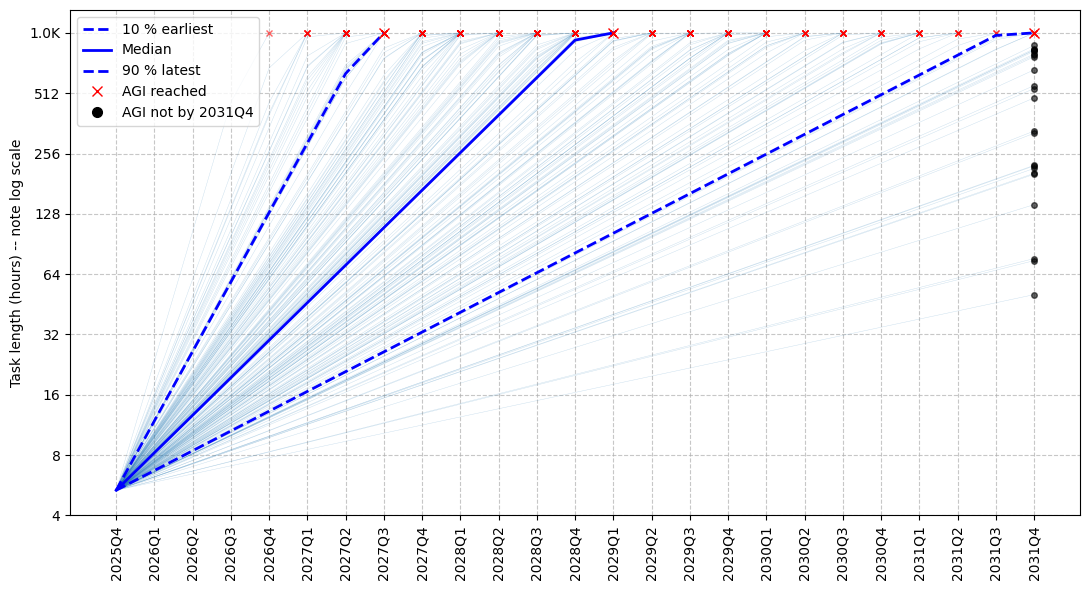

In [4]:
plot_exponential_growth(
    doubling_time_days=doubling_time,
    start_hours=model_data['claude_4p5_opus']['performance_50p'],
    start_date=model_data['claude_4p5_opus']['launch_date'],
    agi_task_length=100_000,
    shift=0,
    n_quarters=24,
    n_samples=100_000,
    n_traces=200,
    max_task_power=10,
)

## Shorter-term predictions

#### Predict Claude 4 Opus

In [5]:
def predict(from_model, for_model, debug=False, verbose=True):
    if isinstance(from_model, str):
        from_model = model_data[from_model]
    if isinstance(for_model, str):
        for_model = model_data[for_model]

    if verbose:
        print(f"PREDICT {from_model['name']} -> {for_model['name']}")
    days_since = (for_model['launch_date'] - from_model['launch_date']).days

    def extrapolation():
        individual_model_idiosyncratic_variation = sq.norm(0.85, 1/0.85, lclip=0.1)
        doublings = days_since / doubling_time
        return from_model['performance_50p'] * (2**doublings) * individual_model_idiosyncratic_variation

    if debug:
        return {'from_model': from_model,
                'for_model': for_model,
                'days_since': days_since,
                'doubling_time': doubling_time,
                'doublings': days_since / doubling_time,
                'from_perf': from_model['performance_50p']}
    else:
        samples = sq.sample(extrapolation, n=50_000, verbose=True)
        mean_ci = sq.get_mean_and_ci(samples, credibility=80)
        if verbose:
            print(f"Predicted: {fmt_worktime(mean_ci['mean'])} (80%CI: {fmt_worktime(mean_ci['ci_low'])} - {fmt_worktime(mean_ci['ci_high'])})")
    
        if for_model.get('performance_50p') and verbose:
            print(f"Actual observed: {for_model['name']} at {for_model['performance_50p']:.1f}hr")
        return samples


def multi_predict(from_models, for_model, verbose=True):
    pred_samples = []
    for from_model in from_models:
        pred_samples.append(predict(from_model, for_model, debug=False, verbose=True))
        if verbose:
            print('')
    if verbose:
            print('- MIXED MODEL -')
    pred_samples = np.concatenate(pred_samples)
    mean_ci = sq.get_mean_and_ci(pred_samples, credibility=80)
    
    if verbose:
        print(f"Predicted: {fmt_worktime(mean_ci['mean'])} (80%CI: {fmt_worktime(mean_ci['ci_low'])} - {fmt_worktime(mean_ci['ci_high'])})")

    bins = [0, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 99999]
    labels = ['<1.5h', '1.5h - 2h', '2h - 2.5h', '2.5h - 3h', '3h - 3.5h', 
              '3.5h - 4h', '4h - 5h', '5h - 6h', '6h - 7h', '7h - 8h',
              '8h - 9h', '9h - 10h', '10h - 11h', '11h - 12h', '12h - 14h', '>14h']
    counts, _ = np.histogram(pred_samples, bins=bins)
    percentages = 100 * counts / len(pred_samples)
    if verbose:
        print('')
        for label, pct in zip(labels, percentages):
            print(f"{label} {pct:.1f}%")
            
    if isinstance(for_model, str):
        for_model = model_data[for_model]
    if for_model.get('performance_50p') and verbose:
        print('')
        print(f"Actual observed: {for_model['name']} at {for_model['performance_50p']:.1f}hr")
        
    return pred_samples

_ = multi_predict(from_models=['o3', 'claude_3p7_sonnet', 'claude_3p5_sonnet_new'], for_model='claude_4_opus')

PREDICT o3 -> Claude 4 Opus


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9216.37it/s]


Predicted: 2.5hr (80%CI: 2.1hr - 2.9hr)
Actual observed: Claude 4 Opus at 1.7hr

PREDICT Claude 3.7 Sonnet -> Claude 4 Opus


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9112.88it/s]


Predicted: 1.6hr (80%CI: 1.2hr - 2.1hr)
Actual observed: Claude 4 Opus at 1.7hr

PREDICT Claude 3.5 Sonnet (new) -> Claude 4 Opus


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9063.55it/s]


Predicted: 1.2hr (80%CI: 33min - 2.0hr)
Actual observed: Claude 4 Opus at 1.7hr

- MIXED MODEL -
Predicted: 1.8hr (80%CI: 42min - 2.7hr)

<1.5h 44.0%
1.5h - 2h 16.9%
2h - 2.5h 22.2%
2.5h - 3h 12.9%
3h - 3.5h 2.4%
3.5h - 4h 0.6%
4h - 5h 0.4%
5h - 6h 0.2%
6h - 7h 0.1%
7h - 8h 0.1%
8h - 9h 0.0%
9h - 10h 0.0%
10h - 11h 0.0%
11h - 12h 0.0%
12h - 14h 0.0%
>14h 0.1%

Actual observed: Claude 4 Opus at 1.7hr


#### Predict GPT5

In [6]:
_ = multi_predict(from_models=['o1', 'o3'], for_model='gpt5')

PREDICT o1 -> GPT-5


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9257.95it/s]


Predicted: 3.1hr (80%CI: 1.2hr - 5.0hr)
Actual observed: GPT-5 at 3.6hr

PREDICT o3 -> GPT-5


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9234.41it/s]


Predicted: 3.8hr (80%CI: 2.6hr - 5.3hr)
Actual observed: GPT-5 at 3.6hr

- MIXED MODEL -
Predicted: 3.4hr (80%CI: 1.3hr - 5.2hr)

<1.5h 14.6%
1.5h - 2h 11.5%
2h - 2.5h 10.4%
2.5h - 3h 15.7%
3h - 3.5h 15.2%
3.5h - 4h 10.5%
4h - 5h 11.0%
5h - 6h 4.6%
6h - 7h 2.3%
7h - 8h 1.2%
8h - 9h 0.8%
9h - 10h 0.5%
10h - 11h 0.3%
11h - 12h 0.3%
12h - 14h 0.3%
>14h 0.9%

Actual observed: GPT-5 at 3.6hr


#### Predict Claude 4.5 Sonnet

In [7]:
_ = multi_predict(from_models=['gpt5', 'claude_4_opus', 'claude_4p1_opus'], for_model='claude_4p5_sonnet')

PREDICT GPT-5 -> Claude 4.5 Sonnet


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9340.70it/s]


Predicted: 4.8hr (80%CI: 3.9hr - 5.8hr)
Actual observed: Claude 4.5 Sonnet at 2.0hr

PREDICT Claude 4 Opus -> Claude 4.5 Sonnet


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9294.24it/s]


Predicted: 3.5hr (80%CI: 2.3hr - 5.1hr)
Actual observed: Claude 4.5 Sonnet at 2.0hr

PREDICT Claude 4.1 Opus -> Claude 4.5 Sonnet


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9242.78it/s]

Predicted: 2.6hr (80%CI: 2.1hr - 3.1hr)
Actual observed: Claude 4.5 Sonnet at 2.0hr

- MIXED MODEL -
Predicted: 3.6hr (80%CI: 2.2hr - 5.3hr)

<1.5h 0.0%
1.5h - 2h 2.8%
2h - 2.5h 20.8%
2.5h - 3h 20.2%
3h - 3.5h 10.5%
3.5h - 4h 9.2%
4h - 5h 22.3%
5h - 6h 9.7%
6h - 7h 2.6%
7h - 8h 0.9%
8h - 9h 0.4%
9h - 10h 0.2%
10h - 11h 0.1%
11h - 12h 0.1%
12h - 14h 0.1%
>14h 0.1%

Actual observed: Claude 4.5 Sonnet at 2.0hr


#### Predict GPT5.1-Codex-Max

In [8]:
_ = multi_predict(from_models=['o1', 'gpt5'], for_model='gpt5.1-codex-max')

PREDICT o1 -> GPT-5.1 Codex Max


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9308.20it/s]


Predicted: 1.6d (80%CI: 1.5hr - 1.5d)
Actual observed: GPT-5.1 Codex Max at 3.9hr

PREDICT GPT-5 -> GPT-5.1 Codex Max


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9380.72it/s]

Predicted: 6.4hr (80%CI: 4.5hr - 1.1d)
Actual observed: GPT-5.1 Codex Max at 3.9hr

- MIXED MODEL -
Predicted: 1.2d (80%CI: 1.8hr - 1.2d)

<1.5h 5.0%
1.5h - 2h 7.3%
2h - 2.5h 6.5%
2.5h - 3h 5.1%
3h - 3.5h 4.0%
3.5h - 4h 4.1%
4h - 5h 15.4%
5h - 6h 18.4%
6h - 7h 12.1%
7h - 8h 6.8%
8h - 9h 3.9%
9h - 10h 2.4%
10h - 11h 1.6%
11h - 12h 1.1%
12h - 14h 1.5%
>14h 4.8%

Actual observed: GPT-5.1 Codex Max at 3.9hr


#### Predict Gemini 3

In [9]:
_ = multi_predict(from_models=['gpt5', 'claude_4_opus', 'gemini_2p5_pro'], for_model='gemini_3')

PREDICT GPT-5 -> Gemini 3 Pro


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9446.60it/s]


Predicted: 6.3hr (80%CI: 4.5hr - 1.1d)
Actual observed: Gemini 3 Pro at 3.9hr

PREDICT Claude 4 Opus -> Gemini 3 Pro


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9351.31it/s]


Predicted: 5.0hr (80%CI: 2.6hr - 7.7hr)
Actual observed: Gemini 3 Pro at 3.9hr

PREDICT Gemini 2.5 Pro -> Gemini 3 Pro


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9386.97it/s]

Predicted: 1.8hr (80%CI: 59min - 2.7hr)
Actual observed: Gemini 3 Pro at 3.9hr

- MIXED MODEL -
Predicted: 4.4hr (80%CI: 1.2hr - 7.5hr)

<1.5h 18.1%
1.5h - 2h 8.0%
2h - 2.5h 5.6%
2.5h - 3h 6.7%
3h - 3.5h 6.5%
3.5h - 4h 5.9%
4h - 5h 13.9%
5h - 6h 13.8%
6h - 7h 8.8%
7h - 8h 4.8%
8h - 9h 2.7%
9h - 10h 1.6%
10h - 11h 1.0%
11h - 12h 0.6%
12h - 14h 0.7%
>14h 1.3%

Actual observed: Gemini 3 Pro at 3.9hr


#### Predict Claude 4.5 Opus

In [10]:
_ = multi_predict(from_models=['gpt5', 'Gemini 3 Pro', 'claude_4_opus', 'claude_4p1_opus', 'claude_4p5_sonnet'], for_model='claude_4p5_opus')

PREDICT GPT-5 -> Claude 4.5 Opus


100%|█████████████████████████████████████████████████████████████████████████████| 50000/50000 [00:05<00:00, 9402.66it/s]


Predicted: 6.6hr (80%CI: 4.6hr - 1.1d)
Actual observed: Claude 4.5 Opus at 5.3hr



KeyError: 'Gemini 3 Pro'

#### Predict GPT5.2

In [ ]:
_ = multi_predict(from_models=['gpt5', 'gpt5.1-codex-max', 'claude_4p1_opus'], for_model='gpt5.2')

#### Predict GPT-5.2-Codex

In [ ]:
_ = multi_predict(from_models=['gpt5', 'gpt5.1-codex-max', 'claude_4p1_opus'], for_model='gpt5.2codex')

#### Predict today

In [ ]:
today = {'name': 'TODAY', 'launch_date': datetime.now()}
_ = multi_predict(from_models=['gpt5', 'gpt5.1-codex-max', 'claude_4p1_opus'], for_model=today)